# ECS708U/P Machine Learning Coursework — Understanding Visual Data (Fashion-MNIST)

**Research question.** What structure exists in Fashion-MNIST, how can different machine-learning
models exploit that structure, and what do their successes and failures teach us about the data
and its representations?

This notebook runs top to bottom with *Restart and run all*. Expensive steps (MLP training)
are cached in `results/`; delete `results/runs/` and `results/checkpoints/` to retrain from scratch.

**Data roles (R1).** Train → fit parameters and scalers. Validation → every choice
(hyperparameters, checkpoints, K, thresholds). Test → used once, at the end, after the test plan is frozen.
Parts 0–3 below therefore report **validation** results only.

## Part 0 — Setup: data and computing (0.1, 0.2)

In [1]:
import json
import platform
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch

from src.data import CLASS_NAMES, SPLIT_SEED, get_splits, load_fashion_mnist
from src.register import log_experiment, show_register

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
pd.set_option("display.precision", 3)

FIG_DIR = "figures"
def savefig(fig, name):
    fig.savefig(f"{FIG_DIR}/{name}.png", bbox_inches="tight", dpi=120)

# 0.2 Record the hardware and software used
print("Machine :", platform.machine(), "|", platform.processor() or "", "| OS:", platform.platform())
print("Python  :", platform.python_version())
print("torch", torch.__version__, "| sklearn", sklearn.__version__, "| numpy", np.__version__)
print("Compute : CPU only (torch threads = %d)" % torch.get_num_threads())

Machine : arm64 | arm | OS: macOS-26.6.2-arm64-arm-64bit
Python  : 3.11.7
torch 2.15.0 | sklearn 1.9.1 | numpy 2.4.6
Compute : CPU only (torch threads = 6)


### 0.1 Fixed data partitions

* The official 60,000 training images are split **stratified** into 50,000 train / 10,000 validation
  with `SPLIT_SEED = 708`. Indices are saved in `splits/splits.npz` and only ever loaded afterwards.
* **CPU-friendly option:** all supervised models in this notebook are fitted on a fixed stratified
  **10,000-image subset of the training partition** (`train_sub`). Validation and test sets are the full
  10,000 images. Using the subset keeps every experiment fast enough to repeat with several seeds,
  and it makes overfitting easier to observe.
* Clustering / feature-extraction subsets: 3,000 train (from the train partition), 1,000 validation
  (from the validation partition) and 1,000 test (from the official test set). The same images are
  used for every representation.
* Labels are used **only** to stratify. Pixel values are rescaled by the fixed constant 1/255,
  which is not learned from data and therefore cannot leak information.

In [2]:
t0 = time.time()
X_off, y_off, X_test, y_test = load_fashion_mnist()
splits = get_splits(y_off, y_test)
print(f"Loaded in {time.time() - t0:.1f}s; split seed = {int(splits['seed'][0])}")

X_tr, y_tr = X_off[splits["train_sub"]], y_off[splits["train_sub"]]   # fitting set (10k)
X_val, y_val = X_off[splits["val"]], y_off[splits["val"]]             # model selection (10k)
# X_test / y_test stay untouched until the final, frozen evaluation.

# Sanity checks: partitions are disjoint and inside the right sets
assert len(np.intersect1d(splits["train"], splits["val"])) == 0
assert np.isin(splits["train_sub"], splits["train"]).all()
assert np.isin(splits["cluster_train"], splits["train"]).all()
assert np.isin(splits["cluster_val"], splits["val"]).all()

sizes = {k: len(v) for k, v in splits.items() if k != "seed"}
counts = pd.DataFrame({
    "train (50k)": np.bincount(y_off[splits["train"]]),
    "val": np.bincount(y_val),
    "train_sub (fit)": np.bincount(y_tr),
    "cluster_train": np.bincount(y_off[splits["cluster_train"]]),
    "cluster_val": np.bincount(y_off[splits["cluster_val"]]),
    "cluster_test": np.bincount(y_test[splits["cluster_test"]]),
    "test": np.bincount(y_test),
}, index=CLASS_NAMES)
counts.loc["TOTAL"] = counts.sum()
print("Partition sizes:", sizes)
counts

Loaded in 0.8s; split seed = 708
Partition sizes: {'train': 50000, 'val': 10000, 'train_sub': 10000, 'cluster_train': 3000, 'cluster_val': 1000, 'cluster_test': 1000}


,train (50k),val,train_sub (fit),cluster_train,cluster_val,cluster_test,test
T-shirt/top,5000,1000,1000,300,100,100,1000
Trouser,5000,1000,1000,300,100,100,1000
Pullover,5000,1000,1000,300,100,100,1000
Dress,5000,1000,1000,300,100,100,1000
Coat,5000,1000,1000,300,100,100,1000
Sandal,5000,1000,1000,300,100,100,1000
Shirt,5000,1000,1000,300,100,100,1000
Sneaker,5000,1000,1000,300,100,100,1000
Bag,5000,1000,1000,300,100,100,1000
Ankle boot,5000,1000,1000,300,100,100,1000


**Table 0.1 (addresses 0.1).** Images per class in every partition. Each class is exactly 10% of every
partition, so stratification preserved the (already balanced) class proportions.

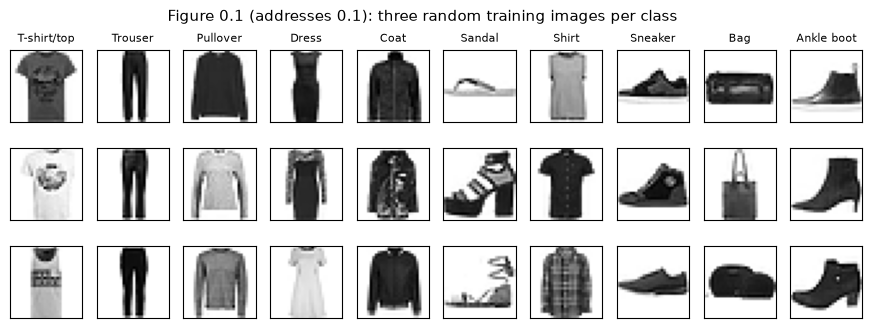

In [3]:
fig, axes = plt.subplots(3, 10, figsize=(11, 3.6))
rng = np.random.default_rng(0)
for c in range(10):
    idx = rng.choice(np.where(y_tr == c)[0], 3, replace=False)
    for r in range(3):
        ax = axes[r, c]
        ax.imshow(X_tr[idx[r]].reshape(28, 28), cmap="gray_r")
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        if r == 0:
            ax.set_title(CLASS_NAMES[c], fontsize=8)
fig.suptitle("Figure 0.1 (addresses 0.1): three random training images per class")
savefig(fig, "fig0_1_examples")
plt.show()

Even from a few examples, the upper-body classes (T-shirt/top, Pullover, Coat, Shirt) look alike:
similar silhouettes with differences in sleeves, collars and texture. Footwear (Sandal, Sneaker,
Ankle boot) forms a second visually related group. We expect most confusions inside these groups.

---
## Part 1 — Classical classification

### 1.1 Models and why they suit this data

| Model | How it predicts | How it is fitted | Complexity control |
|---|---|---|---|
| **Multinomial logistic regression** (LR) | Computes one linear score $w_c^\top x + b_c$ per class, turns the scores into probabilities with softmax and predicts the most probable class. | Minimises the average cross-entropy plus an L2 penalty $\frac{1}{2C}\lVert W\rVert^2$ (L-BFGS). Pixels are standardised with a scaler fitted on the training set only. | `C`: small C → strong penalty → simpler, smoother model; large C → weaker penalty. |
| **k-nearest neighbours** (k-NN) | Finds the k training images closest in Euclidean pixel distance and takes a majority vote. | Nothing is optimised: it stores the training set. | `k`: k = 1 is the most flexible (memorises the training set); larger k averages over more neighbours → smoother boundary. |

**Why these two.** They sit at opposite ends of the model spectrum. LR is *parametric and linear*: it asks
whether the classes can be separated by hyperplanes in pixel space, and its probabilities support the
threshold study in 1.5. k-NN is *non-parametric and local*: it relies entirely on raw-pixel distance,
the same geometry that K-means uses in Part 4, so its errors directly show where pixel distance misleads.
k-NN uses unscaled pixels: all features already share the [0, 1] range, and standardising would inflate
near-constant border pixels.

Both models are fitted on the 10k fitting subset and selected on the validation set.

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def make_lr(C):
    # The scaler is inside the pipeline, so it is fitted on training images only (R2).
    return make_pipeline(StandardScaler(),
                         LogisticRegression(C=C, max_iter=2000, random_state=0))

def make_knn(k):
    return KNeighborsClassifier(n_neighbors=k, metric="euclidean", n_jobs=-1)

### 1.4 Complexity study (run first, because it selects the settings used in 1.2–1.3)

Each model is refitted over a grid of its complexity parameter. We record training and validation
accuracy; the value with the best **validation** accuracy is kept for the rest of Part 1.
For k-NN, training accuracy is computed with each training image included in its own neighbourhood,
which is why k = 1 scores 100% on training data. That is the memorisation we want to show.

In [5]:
C_grid = [1e-4, 1e-3, 1e-2, 1e-1, 1, 10]
k_grid = [1, 3, 5, 9, 15, 25, 51, 101]

lr_rows, knn_rows = [], []
for C in C_grid:
    t0 = time.time()
    m = make_lr(C).fit(X_tr, y_tr)
    lr_rows.append({"C": C, "train_acc": m.score(X_tr, y_tr), "val_acc": m.score(X_val, y_val),
                    "fit_s": time.time() - t0})
for k in k_grid:
    t0 = time.time()
    m = make_knn(k).fit(X_tr, y_tr)
    knn_rows.append({"k": k, "train_acc": m.score(X_tr, y_tr), "val_acc": m.score(X_val, y_val),
                     "time_s": time.time() - t0})
lr_cx, knn_cx = pd.DataFrame(lr_rows), pd.DataFrame(knn_rows)
best_C = float(lr_cx.loc[lr_cx.val_acc.idxmax(), "C"])
best_k = int(knn_cx.loc[knn_cx.val_acc.idxmax(), "k"])
print(f"Selected on validation: LR C = {best_C}, k-NN k = {best_k}")
display(lr_cx); display(knn_cx)

Selected on validation: LR C = 0.01, k-NN k = 5


,C,train_acc,val_acc,fit_s
0,1.000e-04,0.789,0.775,0.380
1,1.000e-03,0.850,0.829,0.685
2,1.000e-02,0.896,0.844,1.260
3,1.000e-01,0.935,0.832,1.851
4,1.000e+00,0.967,0.807,1.648
5,1.000e+01,0.985,0.786,2.965


,k,train_acc,val_acc,time_s
0,1,1.000,0.812,0.992
1,3,0.904,0.820,0.963
2,5,0.878,0.822,0.966
3,9,0.860,0.816,0.978
4,15,0.845,0.813,0.995
5,25,0.831,0.804,1.018
6,51,0.809,0.792,1.114
7,101,0.788,0.776,1.228


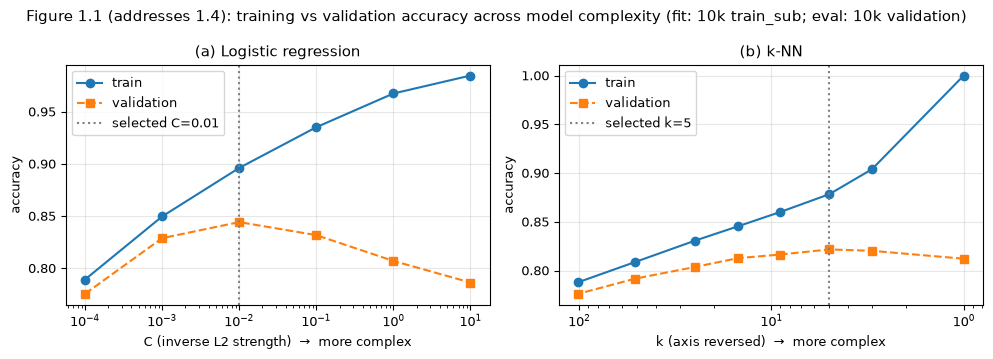

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
ax = axes[0]
ax.semilogx(lr_cx.C, lr_cx.train_acc, "o-", label="train")
ax.semilogx(lr_cx.C, lr_cx.val_acc, "s--", label="validation")
ax.axvline(best_C, color="grey", ls=":", label=f"selected C={best_C:g}")
ax.set_xlabel("C (inverse L2 strength)  →  more complex"); ax.set_ylabel("accuracy")
ax.set_title("(a) Logistic regression"); ax.legend()
ax = axes[1]
ax.semilogx(knn_cx.k, knn_cx.train_acc, "o-", label="train")
ax.semilogx(knn_cx.k, knn_cx.val_acc, "s--", label="validation")
ax.axvline(best_k, color="grey", ls=":", label=f"selected k={best_k}")
ax.invert_xaxis()
ax.set_xlabel("k (axis reversed)  →  more complex"); ax.set_ylabel("accuracy")
ax.set_title("(b) k-NN"); ax.legend()
fig.suptitle("Figure 1.1 (addresses 1.4): training vs validation accuracy across model complexity "
             "(fit: 10k train_sub; eval: 10k validation)")
fig.tight_layout(); savefig(fig, "fig1_1_complexity"); plt.show()

log_experiment(id="E1.4a", task="1.4", question="How does L2 strength affect LR generalisation?",
               hypothesis="Very small C underfits; very large C widens the train-val gap",
               changed_variable="C in " + str(C_grid), fixed_conditions="standardised pixels, lbfgs, max_iter=2000",
               split="fit train_sub / eval val", seed=0, configuration="LogisticRegression multinomial",
               metric="accuracy", result=f"best C={best_C}, val_acc={lr_cx.val_acc.max():.4f}",
               output_path="figures/fig1_1_complexity.png")
log_experiment(id="E1.4b", task="1.4", question="How does k affect k-NN generalisation?",
               hypothesis="k=1 memorises (train 100%); moderate k best on validation",
               changed_variable="k in " + str(k_grid), fixed_conditions="raw pixels, Euclidean, uniform vote",
               split="fit train_sub / eval val", seed="n/a (deterministic)", configuration="KNeighborsClassifier",
               metric="accuracy", result=f"best k={best_k}, val_acc={knn_cx.val_acc.max():.4f}",
               output_path="figures/fig1_1_complexity.png");

**Analysis 1.4 (complexity and generalisation).**
* *Observation.* For both models, training accuracy rises steadily as complexity grows
  (LR: 0.789 → 0.985 as C goes 1e-4 → 10; k-NN: 0.788 → 1.000 as k goes 101 → 1). Validation accuracy
  instead rises and then falls: LR peaks at **C = 0.01 (0.844)**, k-NN peaks at **k = 5 (0.822)**.
* *Interpretation.* On the left of each panel the model is too simple (underfitting): train and
  validation are both low and close together, so the error comes from bias. On the right the
  train–validation gap widens (LR at C = 10: 0.985 vs 0.786, a 20-point gap; k-NN at k = 1: 1.000 vs 0.812).
  The model is fitting details of these particular 10k images that do not carry over to new images (variance).
  The best validation point balances the two. This is the bias–variance trade-off.
* Even a linear model can overfit: with 784 inputs × 10 classes ≈ 7,850 weights and only 10k images,
  weak regularisation lets LR fit noise. k-NN's validation curve is flat between k = 3 and k = 15
  (0.816–0.822), so its exact choice of k matters little.
* *Caveat.* The difference between the best and runner-up settings (e.g. k = 3 vs 5: 0.820 vs 0.822) is
  about 20 images out of 10,000 and should not be over-interpreted.

### 1.2 Metrics: overall and per class (validation set, selected models)

In [7]:
lr = make_lr(best_C).fit(X_tr, y_tr)
knn = make_knn(best_k).fit(X_tr, y_tr)
t0 = time.time(); pred_lr = lr.predict(X_val); proba_lr = lr.predict_proba(X_val); t_lr = time.time() - t0
t0 = time.time(); pred_knn = knn.predict(X_val); t_knn = time.time() - t0
print(f"Validation prediction time: LR {t_lr:.2f}s, k-NN {t_knn:.2f}s (10,000 images)")

def per_class_table(y_true, y_pred):
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=range(10), zero_division=0)
    return pd.DataFrame({"precision": p, "recall": r, "f1": f, "support": s}, index=CLASS_NAMES)

tab_lr, tab_knn = per_class_table(y_val, pred_lr), per_class_table(y_val, pred_knn)
summary = pd.concat({f"LR (C={best_C:g})": tab_lr, f"k-NN (k={best_k})": tab_knn}, axis=1)
acc_lr, acc_knn = accuracy_score(y_val, pred_lr), accuracy_score(y_val, pred_knn)
print(f"Overall validation accuracy: LR {acc_lr:.4f} ({(pred_lr == y_val).sum()}/{len(y_val)}),  "
      f"k-NN {acc_knn:.4f} ({(pred_knn == y_val).sum()}/{len(y_val)})")
summary

Validation prediction time: LR 0.01s, k-NN 0.48s (10,000 images)
Overall validation accuracy: LR 0.8442 (8442/10000),  k-NN 0.8216 (8216/10000)


LR (C=0.01)                       k-NN (k=5)                      
              precision recall     f1 support  precision recall     f1 support
T-shirt/top       0.786  0.822  0.804    1000      0.720  0.849  0.779    1000
Trouser           0.968  0.972  0.970    1000      0.989  0.953  0.970    1000
Pullover          0.744  0.757  0.751    1000      0.687  0.788  0.734    1000
Dress             0.853  0.854  0.854    1000      0.853  0.854  0.854    1000
Coat              0.750  0.747  0.748    1000      0.741  0.701  0.720    1000
Sandal            0.933  0.910  0.922    1000      0.992  0.757  0.859    1000
Shirt             0.619  0.576  0.597    1000      0.623  0.505  0.558    1000
Sneaker           0.906  0.912  0.909    1000      0.840  0.925  0.881    1000
Bag               0.946  0.947  0.947    1000      0.969  0.923  0.945    1000
Ankle boot        0.925  0.945  0.935    1000      0.846  0.961  0.900    1000

**Table 1.1 (addresses 1.2).** Per-class precision, recall and F1 on the validation set, with the number of
true images per class (*support*). Recall = correct / support for that class; precision = correct / all
images predicted as that class.

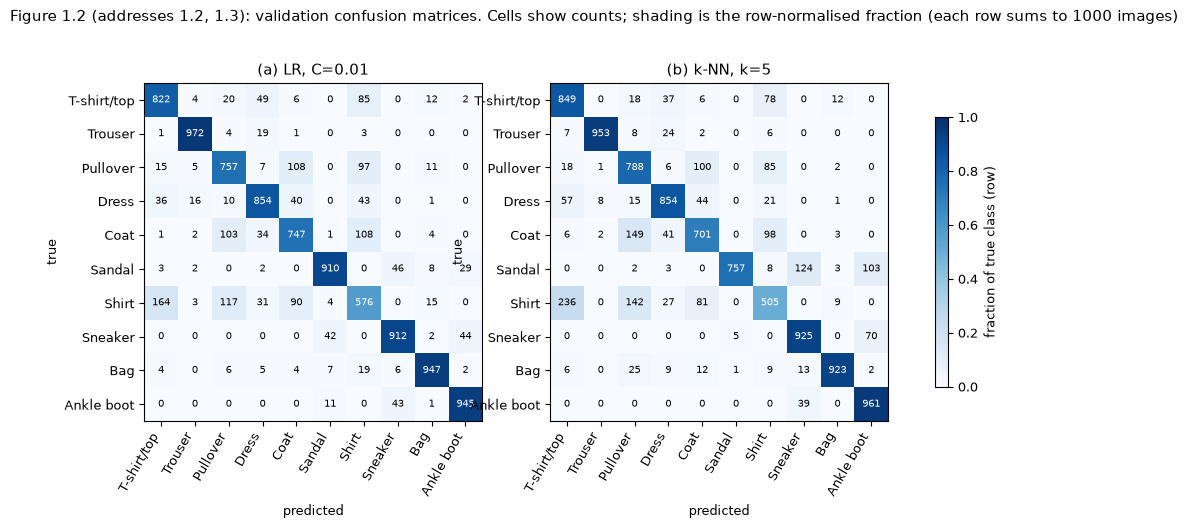

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, pred, name in [(axes[0], pred_lr, f"(a) LR, C={best_C:g}"), (axes[1], pred_knn, f"(b) k-NN, k={best_k}")]:
    cm = confusion_matrix(y_val, pred, labels=range(10))
    im = ax.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for i in range(10):
        for j in range(10):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                    color="white" if cm[i, j] > 500 else "black")
    ax.set_xticks(range(10), CLASS_NAMES, rotation=60, ha="right"); ax.set_yticks(range(10), CLASS_NAMES)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(name); ax.grid(False)
fig.colorbar(im, ax=axes, shrink=0.7, label="fraction of true class (row)")
fig.suptitle("Figure 1.2 (addresses 1.2, 1.3): validation confusion matrices. Cells show counts; "
             "shading is the row-normalised fraction (each row sums to 1000 images)")
savefig(fig, "fig1_2_confusion"); plt.show()

log_experiment(id="E1.2", task="1.2", question="How well do the selected LR and k-NN classify each class?",
               hypothesis="Upper-body garments (Shirt, Pullover, Coat, T-shirt) are hardest",
               changed_variable="model", fixed_conditions="same train_sub / same val images",
               split="fit train_sub / eval val", seed=0,
               configuration=f"LR C={best_C}; kNN k={best_k}", metric="accuracy, per-class P/R/F1",
               result=f"LR {acc_lr:.4f}; kNN {acc_knn:.4f}", output_path="figures/fig1_2_confusion.png");

### 1.3 Error analysis: comparing the two models on the same images

In [9]:
ok_lr, ok_knn = pred_lr == y_val, pred_knn == y_val
agree = pd.DataFrame([[np.sum(ok_lr & ok_knn), np.sum(ok_lr & ~ok_knn)],
                      [np.sum(~ok_lr & ok_knn), np.sum(~ok_lr & ~ok_knn)]],
                     index=["LR correct", "LR wrong"], columns=["k-NN correct", "k-NN wrong"])
both_wrong_same = np.sum(~ok_lr & ~ok_knn & (pred_lr == pred_knn))
print(f"Both wrong on {agree.iloc[1, 1]} images; on {both_wrong_same} of them they predict the SAME wrong class.")
display(agree)

per_class_err = pd.DataFrame({
    "support": np.bincount(y_val, minlength=10),
    "both correct": np.bincount(y_val[ok_lr & ok_knn], minlength=10),
    "only LR correct": np.bincount(y_val[ok_lr & ~ok_knn], minlength=10),
    "only k-NN correct": np.bincount(y_val[~ok_lr & ok_knn], minlength=10),
    "both wrong": np.bincount(y_val[~ok_lr & ~ok_knn], minlength=10)}, index=CLASS_NAMES)
per_class_err

Both wrong on 1013 images; on 754 of them they predict the SAME wrong class.


,k-NN correct,k-NN wrong
LR correct,7671,771
LR wrong,545,1013


,support,both correct,only LR correct,only k-NN correct,both wrong
T-shirt/top,1000,772,50,77,101
Trouser,1000,946,26,7,21
Pullover,1000,662,95,126,117
Dress,1000,807,47,47,99
Coat,1000,608,139,93,160
Sandal,1000,745,165,12,78
Shirt,1000,416,160,89,335
Sneaker,1000,874,38,51,37
Bag,1000,911,36,12,41
Ankle boot,1000,930,15,31,24


**Table 1.2 (addresses 1.3).** Agreement between the two models on the *same* 10,000 validation images,
overall and per true class.

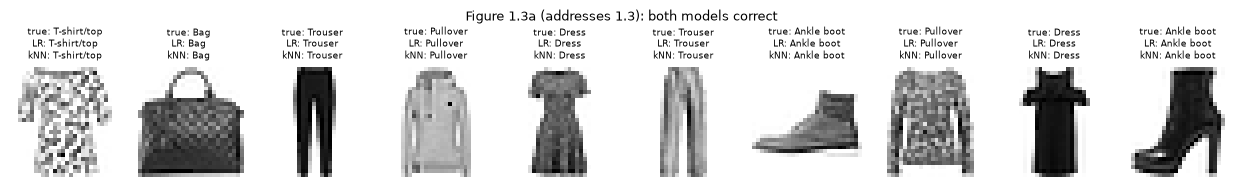

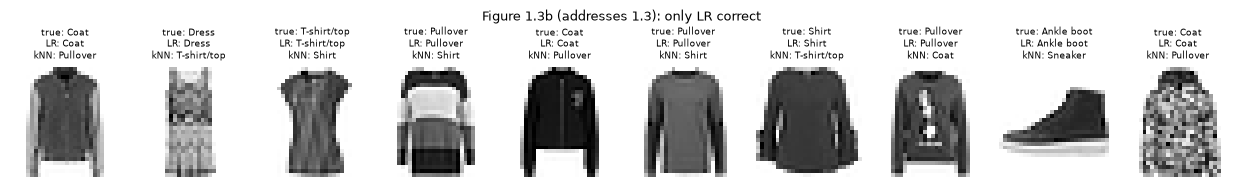

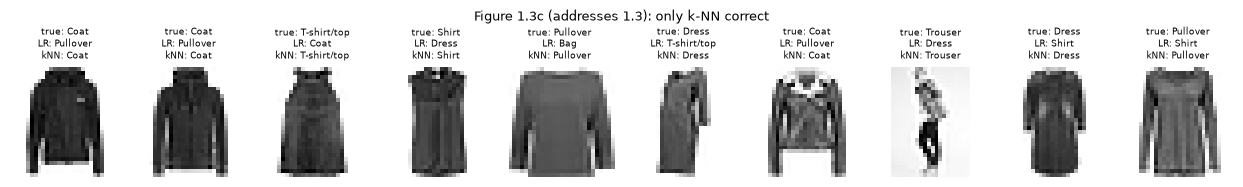

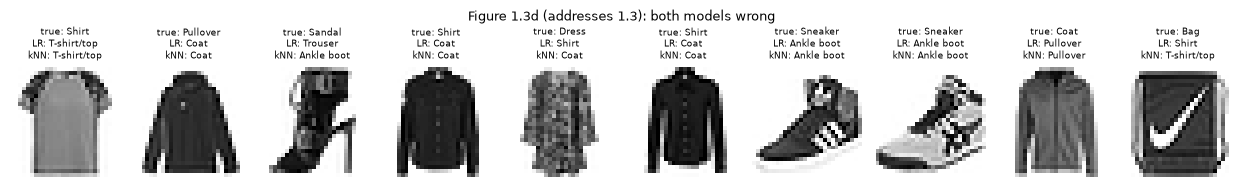

In [10]:
def show_grid(indices, title, fname, n=10):
    rng = np.random.default_rng(1)
    indices = rng.choice(indices, min(n, len(indices)), replace=False) if len(indices) else []
    fig, axes = plt.subplots(1, n, figsize=(1.25 * n, 2.0))
    for ax in axes: ax.axis("off")
    for ax, i in zip(axes, indices):
        ax.imshow(X_val[i].reshape(28, 28), cmap="gray_r")
        ax.set_title(f"true: {CLASS_NAMES[y_val[i]]}\nLR: {CLASS_NAMES[pred_lr[i]]}\n"
                     f"kNN: {CLASS_NAMES[pred_knn[i]]}", fontsize=6.5)
    fig.suptitle(title, fontsize=9); fig.tight_layout(); savefig(fig, fname); plt.show()

show_grid(np.where(ok_lr & ok_knn)[0], "Figure 1.3a (addresses 1.3): both models correct", "fig1_3a_both_correct")
show_grid(np.where(ok_lr & ~ok_knn)[0], "Figure 1.3b (addresses 1.3): only LR correct", "fig1_3b_only_lr")
show_grid(np.where(~ok_lr & ok_knn)[0], "Figure 1.3c (addresses 1.3): only k-NN correct", "fig1_3c_only_knn")
show_grid(np.where(~ok_lr & ~ok_knn)[0], "Figure 1.3d (addresses 1.3): both models wrong", "fig1_3d_both_wrong")

In [11]:
cm_l, cm_k = confusion_matrix(y_val, pred_lr), confusion_matrix(y_val, pred_knn)
pairs = []
for i in range(10):
    for j in range(10):
        if i != j:
            pairs.append({"true": CLASS_NAMES[i], "predicted": CLASS_NAMES[j],
                          "LR errors": cm_l[i, j], "k-NN errors": cm_k[i, j]})
top_pairs = pd.DataFrame(pairs).assign(total=lambda d: d["LR errors"] + d["k-NN errors"]) \
    .sort_values("total", ascending=False).head(8).reset_index(drop=True)
top_pairs

,true,predicted,LR errors,k-NN errors,total
0,Shirt,T-shirt/top,164,236,400
1,Shirt,Pullover,117,142,259
2,Coat,Pullover,103,149,252
3,Pullover,Coat,108,100,208
4,Coat,Shirt,108,98,206
5,Pullover,Shirt,97,85,182
6,Shirt,Coat,90,81,171
7,Sandal,Sneaker,46,124,170


**Table 1.3 (addresses 1.3).** The eight most frequent confusions (true → predicted) on validation, out of
1,000 images per true class.

**Analysis 1.3 (easy and hard classes, and what the errors tell us).**
* *Observation.* **Easy classes**: Trouser, Bag and Ankle boot (≥ 0.92 recall for both models). Their
  silhouettes are distinctive: two legs, a box with a handle, a tall boot shape. **Hard classes**: Shirt
  (recall 0.576 LR / 0.505 k-NN), then Coat and Pullover (~0.70–0.79). Every top-7 confusion in Table 1.3
  is *between upper-body garments* (Shirt → T-shirt/top is the largest: 164 LR and 236 k-NN errors out of
  1,000 shirts). The only cross-group exception in the top 8 is Sandal → Sneaker.
* *Observation.* The two models agree a lot: 7,671 images are correct for both, and on 754 of the
  1,013 images where both are wrong they make the **same** wrong prediction.
* *Interpretation.* Errors made by two very different models (one linear and global, one local and
  memory-based) are likely caused by the **data/representation**, not by a particular model. In raw
  pixels, a shirt and a T-shirt are close: both are a bright torso-shaped blob. The distinguishing cues
  (sleeve length, buttons, collar) occupy few pixels, so they contribute little to Euclidean distance or
  to a linear score. Some "both wrong" images (Figure 1.3d) are genuinely ambiguous even to a human.
* *Where they differ.* LR wins clearly on **Sandal** (165 vs 12 images that only one model gets right).
  Sandals are sparse, strappy images whose pixel pattern varies a lot, so their nearest neighbours in
  pixel space are often sneakers (k-NN: 124 Sandal → Sneaker errors vs 46 for LR). LR instead learns which
  pixels matter (e.g. the empty gaps of a sandal). k-NN is relatively better on Pullover and T-shirt/top,
  where a close stored example of the same style can beat a single linear boundary (Figure 1.3c).
* *Hypothesis for later parts.* The upper-body group should also appear merged when we cluster raw
  pixels (Part 4), and a representation learned with labels (Part 5) should separate it better.

### 1.5 Decisions and costs: a binary decision with a threshold

**Decision problem (my own).** A returns warehouse sorts items automatically and sends anything it
believes is a **Shirt** to a manual inspection station (shirts are often returned for button and collar
damage). Positive = Shirt, negative = any other class.
* **False negative (FN)**: a Shirt is not inspected → a damaged item may be resold (costly).
* **False positive (FP)**: a non-Shirt is inspected → a few minutes of staff time are wasted (cheap).

We use the LR probability $p(\text{Shirt}\mid x)$ as a score and predict *Shirt* when it is $\ge t$.
Shirt is the hardest class (Table 1.1), so it is the problem where the threshold matters most.
For illustration we assume an FN costs **5×** an FP and choose $t$ on **validation** data to minimise
the total cost. The default argmax rule corresponds to roughly $t\approx 0.5$.

Positives (Shirt) = 1000, negatives = 9000;  ROC-AUC = 0.935


,t,TP,FP,FN,TN,FNR (missed shirts),FPR (false alarms),precision,"cost (FN=5, FP=1)"
9,0.10,872,1504,128,7496,0.128,0.167,0.367,2144
18,0.19,789,911,211,8089,0.211,0.101,0.464,1966
19,0.20,781,871,219,8129,0.219,0.097,0.473,1966
29,0.30,685,544,315,8456,0.315,0.060,0.557,2119
49,0.50,500,237,500,8763,0.500,0.026,0.678,2737
69,0.70,302,88,698,8912,0.698,0.010,0.774,3578
89,0.90,56,15,944,8985,0.944,0.002,0.789,4735


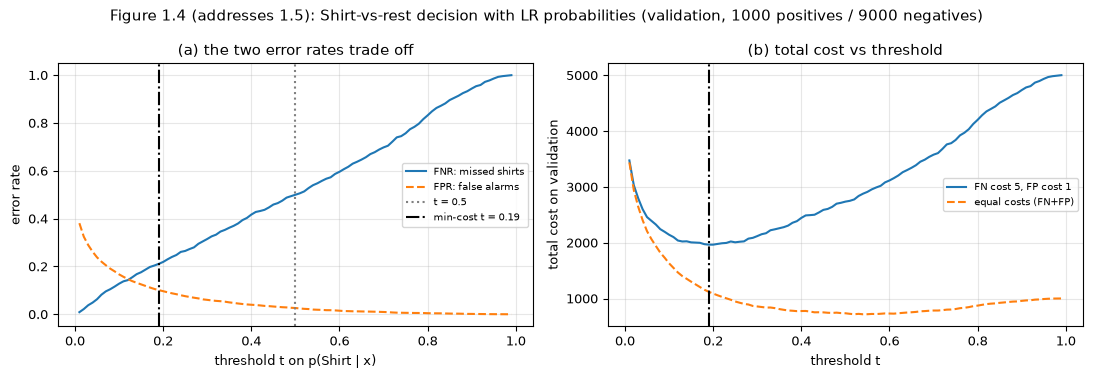

In [12]:
from sklearn.metrics import precision_recall_curve, roc_auc_score

POS = CLASS_NAMES.index("Shirt")
score = proba_lr[:, POS]; is_pos = (y_val == POS)
thresholds = np.linspace(0.01, 0.99, 99)
rows = []
for t in thresholds:
    pred_pos = score >= t
    tp = np.sum(pred_pos & is_pos); fp = np.sum(pred_pos & ~is_pos)
    fn = np.sum(~pred_pos & is_pos); tn = np.sum(~pred_pos & ~is_pos)
    rows.append({"t": t, "TP": tp, "FP": fp, "FN": fn, "TN": tn,
                 "FNR (missed shirts)": fn / is_pos.sum(), "FPR (false alarms)": fp / (~is_pos).sum(),
                 "precision": tp / max(tp + fp, 1), "cost (FN=5, FP=1)": 5 * fn + fp})
thr = pd.DataFrame(rows)
t_cost = thr.loc[thr["cost (FN=5, FP=1)"].idxmin(), "t"]
t_half = thr.iloc[(thr.t - 0.5).abs().argmin()]
print(f"Positives (Shirt) = {is_pos.sum()}, negatives = {(~is_pos).sum()};  ROC-AUC = {roc_auc_score(is_pos, score):.3f}")
display(thr[thr.t.round(2).isin([0.1, 0.2, 0.3, round(t_cost, 2), 0.5, 0.7, 0.9])].round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.plot(thr.t, thr["FNR (missed shirts)"], "-", label="FNR: missed shirts")
ax.plot(thr.t, thr["FPR (false alarms)"], "--", label="FPR: false alarms")
ax.axvline(0.5, color="grey", ls=":", label="t = 0.5")
ax.axvline(t_cost, color="k", ls="-.", label=f"min-cost t = {t_cost:.2f}")
ax.set_xlabel("threshold t on p(Shirt | x)"); ax.set_ylabel("error rate"); ax.legend(fontsize=7)
ax.set_title("(a) the two error rates trade off")
ax = axes[1]
ax.plot(thr.t, thr["cost (FN=5, FP=1)"], "-", label="FN cost 5, FP cost 1")
ax.plot(thr.t, thr.FN + thr.FP, "--", label="equal costs (FN+FP)")
ax.axvline(t_cost, color="k", ls="-.")
ax.set_xlabel("threshold t"); ax.set_ylabel("total cost on validation"); ax.legend(fontsize=7)
ax.set_title("(b) total cost vs threshold")
fig.suptitle("Figure 1.4 (addresses 1.5): Shirt-vs-rest decision with LR probabilities "
             f"(validation, {is_pos.sum()} positives / {(~is_pos).sum()} negatives)")
fig.tight_layout(); savefig(fig, "fig1_4_threshold"); plt.show()

log_experiment(id="E1.5", task="1.5", question="How does the threshold trade missed shirts against false alarms?",
               hypothesis="With FN 5x costlier, the best threshold is well below 0.5",
               changed_variable="threshold t in [0.01, 0.99]", fixed_conditions=f"LR C={best_C}, validation scores",
               split="fit train_sub / eval val", seed=0, configuration="Shirt (pos) vs rest, cost FN=5 FP=1",
               metric="FNR, FPR, total cost", result=f"min-cost t={t_cost:.2f}",
               output_path="figures/fig1_4_threshold.png");

**Analysis 1.5 (threshold trade-off).**
* *Observation.* Lowering the threshold catches more shirts but raises more false alarms (Figure 1.4a):
  at t = 0.5 the system misses **50%** of shirts (FNR 0.50) with a 2.6% false-alarm rate; at t = 0.1 it
  misses only 12.8% but flags 16.7% of non-shirts (1,504 items). ROC-AUC = 0.935, so the score ranks
  shirts above non-shirts well, but the classes overlap.
* With FN cost 5 and FP cost 1, validation cost is minimised at **t ≈ 0.19–0.20** (cost 1,966 vs 2,737 at
  t = 0.5, a 28% reduction). The cost curve is flat around its minimum, so the precise value is not critical.
* *Interpretation.* The probability threshold is a **decision** choice separate from the model. The
  default 0.5 implicitly assumes equal costs, and under the stated costs it is far from optimal. Precision
  at the chosen threshold is only ~0.46, because negatives outnumber positives 9:1: even a modest FPR
  creates many false alarms.
* *Caveat.* The threshold is chosen on validation. Its cost on unseen data will be measured once in the
  final test evaluation, and the 5:1 cost ratio is an assumption of the scenario, not a measured fact.